# Azure OpenAI streaming latency

Measure client-observed streaming latency with Microsoft Entra ID and display every captured metric. The notebook supports both the Chat Completions path from support case `2607310040006239` and the current Microsoft Foundry Responses streaming example.

No prompt text, generated text, access token, or API key is stored in the results. The optional raw-event preview displays a few generated deltas in the notebook but does not persist them to JSONL.

## 1. Configuration

The notebook finds the nearest `.env`, using the same required variables as `../web-search/.env`. Install dependencies once with `python -m pip install openai azure-identity python-dotenv pandas httpx matplotlib`.

In [ ]:
from __future__ import annotations

import hashlib
import json
import os
import time
import uuid
from datetime import datetime, timezone
from itertools import pairwise
from pathlib import Path
from urllib.parse import urlsplit

import httpx
import matplotlib.pyplot as plt
import pandas as pd
from azure.identity import DefaultAzureCredential, get_bearer_token_provider
from dotenv import load_dotenv
from openai import OpenAI

try:
    from IPython.display import display
except ImportError:

    def display(value) -> None:
        print(value.to_string() if hasattr(value, "to_string") else value)


def find_project_dir() -> Path:
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / ".env").exists():
            return candidate
    raise FileNotFoundError("No .env found in the current directory or its parents.")


def required_env(name: str) -> str:
    value = os.getenv(name, "").strip()
    if not value:
        raise ValueError(f"Set {name} in .env.")
    return value


def normalize_base_url(endpoint: str) -> str:
    endpoint = endpoint.rstrip("/")
    if not endpoint.endswith("/openai/v1"):
        endpoint += "/openai/v1"
    return endpoint + "/"


PROJECT_DIR = find_project_dir()
load_dotenv(PROJECT_DIR / ".env", override=True)

BASE_URL = normalize_base_url(required_env("AZURE_OPENAI_ENDPOINT"))
DEPLOYMENT = required_env("AZURE_OPENAI_DEPLOYMENT")
TENANT_ID = required_env("AZURE_TENANT_ID")
TOKEN_SCOPE = os.getenv("AZURE_OPENAI_TOKEN_SCOPE", "https://ai.azure.com/.default")
API = os.getenv("AZURE_OPENAI_STREAMING_API", "chat-completions")
LABEL = os.getenv("STREAMING_TEST_LABEL", "direct")
RUNS = int(os.getenv("STREAMING_RUNS", "5"))
WARMUP_RUNS = int(os.getenv("STREAMING_WARMUP_RUNS", "1"))
DELAY_SECONDS = float(os.getenv("STREAMING_DELAY_SECONDS", "1"))
TIMEOUT_SECONDS = float(os.getenv("STREAMING_TIMEOUT_SECONDS", "120"))
MAX_OUTPUT_TOKENS = int(os.getenv("AZURE_OPENAI_MAX_COMPLETION_TOKENS", "256"))
REASONING_EFFORT = os.getenv("AZURE_OPENAI_REASONING_EFFORT") or None
RAW_EVENT_LIMIT = int(os.getenv("STREAMING_RAW_EVENT_LIMIT", "0"))
PATH_NAME = os.getenv("STREAMING_PATH", LABEL).upper()
TIER = os.getenv("STREAMING_TIER", "dev")
SERVING = os.getenv("STREAMING_SERVING", "False")
WORKSPACE = os.getenv("STREAMING_WORKSPACE", "not set")
API_VERSION = os.getenv("AZURE_OPENAI_API_VERSION", "v1")

PROMPT = f"""
    {time.strftime('%Y-%m-%d %H:%M:%S', time.localtime())} 
    "STREAMING_PROMPT "
    c3c273be-9ad9-4132-acbf-adb9ad1aa407. You are an expert in summarizing client reports for bankers and advisors. Generate a client summary using the exact section structure below.
General Instructions:
1. Use only provided input data. Do not infer, assume, or invent.
2. Keep wording concise, factual, and professional.
3. If an entire section input is empty or missing, output one bullet: "No data available" only where instructed. Otherwise, skip only null or empty fields.
4. Inputs are JSON. Use only fields explicitly requested for each section.
5. Use "Client", not "Customer". Use neutral pronouns (they/their).
6. Mask sensitive numbers (SSNs, card numbers, and any 16-digit number). Do not mask phone numbers or emails.
7. Clean extracted values by trimming whitespace and stray symbols.
8. Use Markdown bullets exactly as specified.
9. Output valid Markdown only.
10. Use the exact headers and subheaders below. Do not add sections or horizontal rules.
11. Heading levels are mandatory:
- Main headers ("Highlights", "Call Summaries", and "Opportunities") use ##.
- Subheaders ("Discover Needs", "Meetings", "Open Opportunities", and "Closed Opportunities") use ####.
- Sub-subheaders ("Upcoming Meetings" and "Past Meetings") use ######.
12. Each record's `RecordUrl` already contains a fully formatted Markdown hyperlink. Use it verbatim wherever specified.

## Highlights

Input fields: `clientRecord`, `relatedBusinesses`, `relatedContacts`, `updatedDiscoverNeeds`, `clientPastMeetings`, and `clientFutureMeetings`.

Provide up to five bullets total, with no subheader:
- Up to three bullets containing key profile details from `clientRecord` only, including name, age, client type, client since date, last activity date, assigned banker, branch, occupation, and family details when present.
- Up to one bullet containing financial goals or other key messages from `clientRecord`. Skip it when no data is available. Do not use `updatedDiscoverNeeds` here.
- If `IsPersonAccount` is true, output: `Related Business Names: <list>`. Build `<list>` by joining the `RecordUrl` values from `relatedBusinesses` with commas. If the list is null or empty, use `No data available`.
- If `IsPersonAccount` is false, output: `Related Contact Names: <list>`. Build `<list>` by joining the `RecordUrl` values from `relatedContacts` with commas. If the list is null or empty, use `No data available`.

Notes:
- Only the related-entities bullet may contain hyperlinks.
- Preferred language defaults to English. Mention `languagePreferenceExpanded` only when it is non-null and not English.

#### Discover Needs
Summarize `updatedDiscoverNeeds` as plain-text bullets.
- Skip null or empty descriptions.
- Summarize long descriptions to their key points.
- If the entire list is empty, output `- No data available`.

#### Meetings

###### Upcoming Meetings
Use `clientFutureMeetings` in input order.
- Format each bullet as `RecordUrl: subject and description`.
- Use `RecordUrl` verbatim in place of the plain date and time.
- Skip null or empty descriptions and summarize long descriptions.
- If the list is null or empty, output `- No data available`.

###### Past Meetings
Use `clientPastMeetings` as provided.

Always print this non-bullet line first:
Here are the most recent meetings in the past three years (up to 5):

- Format each meeting as `RecordUrl: subject and description`.
- Use `RecordUrl` verbatim in place of the plain date.
- Skip null or empty descriptions and summarize long descriptions.
- If the list is null or empty, print the line above followed by `- No data available`.

Here is the input of "ClientRecord":

{{  "clientRecord": {{
    "Name": "CORWITT LLC",
    "languagePreferenceExpanded": "N/A",
    "IsPersonAccount": false,
    "hhLastActivityDate": "Jul 21, 2026",
    "Description": null,
    "customerType": "Business Premier",
    "customerSinceDate": "Dec 28, 2007",
    "branch": null,
    "assignedBanker": null
  }}
}}

Provide a 1200 word response.
"""


OUTPUT_PATH = PROJECT_DIR / "results" / "notebook-streaming-latency.jsonl"

if API not in {"chat-completions", "responses"}:
    raise ValueError("API must be 'chat-completions' or 'responses'.")
if MAX_OUTPUT_TOKENS <= 0:
    raise ValueError("MAX_OUTPUT_TOKENS must be greater than zero.")
if RAW_EVENT_LIMIT < 0:
    raise ValueError("RAW_EVENT_LIMIT cannot be negative.")

## 2. Entra-authenticated client

The SDK receives a renewable bearer-token provider. Retries are disabled so each row represents exactly one HTTP request.

In [34]:
credential = DefaultAzureCredential()
token_provider = get_bearer_token_provider(credential, TOKEN_SCOPE)
client = OpenAI(
    base_url=BASE_URL,
    api_key=token_provider,
    max_retries=0,
    timeout=httpx.Timeout(TIMEOUT_SECONDS, connect=min(TIMEOUT_SECONDS, 30)),
)


def mask_identifier(value: str) -> str:
    return f"{value[:4]}...{value[-4:]}" if len(value) > 8 else "***"


gateway_description = "no gateway" if PATH_NAME == "DIRECT" else "gateway"
print("=== AUTH DETAILS ===")
print(f"credential : {type(credential).__name__}")
print(f"tenant     : {mask_identifier(TENANT_ID)}")
print(f"scope      : {TOKEN_SCOPE}")
print("token      : acquired on demand; value not displayed")
print("=== END AUTH DETAILS ===")
print()
print(
    f"path      : {PATH_NAME} ({gateway_description}, tier={TIER}, serving={SERVING})"
)
print(f"endpoint  : {BASE_URL}")
print(f"workspace : {WORKSPACE}")
print(f"model     : {DEPLOYMENT}    api: {API_VERSION}")

=== AUTH DETAILS ===
credential : DefaultAzureCredential
tenant     : 16b3...b6d3
scope      : https://ai.azure.com/.default
token      : acquired on demand; value not displayed
=== END AUTH DETAILS ===

path      : DIRECT (no gateway, tier=dev, serving=False)
endpoint  : https://jacwang-foundryonly.cognitiveservices.azure.com/openai/v1/
workspace : not set
model     : gpt-5.4-mini    api: v1


## 3. Measure the raw SSE stream

Here, **raw response** means the HTTP metadata plus the non-empty SSE lines returned by `response.iter_lines()` after the SDK has decoded the transport. It is not a packet capture or the original compressed TCP bytes.

A streaming response is not one JSON document. It is a sequence of Server-Sent Event lines:

```text
HTTP/1.1 200
content-type: text/event-stream
apim-request-id: <request-id>

data: {"choices":[{"delta":{"role":"assistant"}}]}
data: {"choices":[{"delta":{"content":"1"}}]}
data: {"choices":[],"usage":{...}}
data: [DONE]
```

For Chat Completions, visible TTFT starts at the first non-empty `choices[0].delta.content`; a preceding role-only delta is an SSE event but not visible content. For Responses, visible TTFT starts at the first `response.output_text.delta` event with a non-empty `delta`.

> **Measurement boundary:** Azure does not include a per-token server-generation timestamp in these events. Therefore the client cannot calculate `token generated → SSE received`. The notebook measures when each SSE/content chunk is received and the gap since the previous received SSE. A content delta can contain zero, one, or multiple tokens. Chat Completions may include a `created` field, but it is coarse completion/chunk metadata repeated across events—not a per-token generation timestamp.

In [35]:
CORRELATION_HEADERS = (
    "apim-request-id",
    "request-id",
    "x-request-id",
    "x-ms-request-id",
    "x-ms-client-request-id",
    "x-ms-region",
    "openai-processing-ms",
    "x-envoy-upstream-service-time",
    "server-timing",
    "traceparent",
    "x-correlation-id",
)
CHECKPOINT_FIELDS = (
    "pre_inference_ms",
    "engine_ttft_ms",
    "service_ttft_ms",
    "user_visible_ttft_ms",
    "engine_tbt_ms",
    "engine_ttlt_ms",
    "service_ttlt_ms",
)


def ms(later_ns: int | None, earlier_ns: int | None) -> float | None:
    if later_ns is None or earlier_ns is None:
        return None
    return round((later_ns - earlier_ns) / 1_000_000, 3)


def flatten(result: dict, prefix: str, value) -> None:
    if isinstance(value, dict):
        for key, child in value.items():
            flatten(result, f"{prefix}_{key}", child)
    elif isinstance(value, (str, int, float, bool)) or value is None:
        result[prefix] = value


def extract_latency_checkpoint(payload: dict) -> dict:
    checkpoint = {}
    containers = [payload, payload.get("response")]
    for container in containers:
        if not isinstance(container, dict):
            continue
        for name in ("serving_latency_checkpoint", "latency_checkpoint"):
            value = container.get(name)
            if isinstance(value, dict):
                checkpoint.update(value)
        for field in CHECKPOINT_FIELDS:
            if field in container:
                checkpoint[field] = container[field]
    return checkpoint


def measure_stream(run: int, *, warmup: bool = False) -> tuple[dict, dict, list[dict]]:
    client_request_id = str(uuid.uuid4())
    started_utc = datetime.now(timezone.utc).isoformat()
    correlation_headers = {
        "x-ms-client-request-id": client_request_id,
        "x-client-request-id": client_request_id,
    }

    if API == "responses":
        request = {
            "model": DEPLOYMENT,
            "input": PROMPT,
            "stream": True,
            "max_output_tokens": MAX_OUTPUT_TOKENS,
            "extra_headers": correlation_headers,
        }
        if REASONING_EFFORT:
            request["reasoning"] = {"effort": REASONING_EFFORT}
        context = client.responses.with_streaming_response.create(**request)
    else:
        request = {
            "model": DEPLOYMENT,
            "messages": [{"role": "user", "content": PROMPT}],
            "stream": True,
            "stream_options": {"include_usage": True},
            "max_completion_tokens": MAX_OUTPUT_TOKENS,
            "extra_headers": correlation_headers,
        }
        if REASONING_EFFORT:
            request["reasoning_effort"] = REASONING_EFFORT
        context = client.chat.completions.with_streaming_response.create(**request)

    started_ns = time.perf_counter_ns()
    first_sse_ns = first_content_ns = last_content_ns = None
    previous_sse_ns = None
    event_timeline = []
    raw_sse_lines = []
    raw_line_count = 0
    event_count = content_event_count = output_chars = 0
    usage, model, finish_reason = {}, None, None
    latency_checkpoint = {}

    with context as response:
        headers_ns = time.perf_counter_ns()
        response_headers = {
            key.lower(): value for key, value in response.headers.items()
        }
        response_request_id = response.request_id
        response_status = response.status_code
        response_http_version = response.http_version

        for raw_line in response.iter_lines():
            line = raw_line.decode() if isinstance(raw_line, bytes) else raw_line
            line = line.strip()
            if line:
                raw_line_count += 1
                if len(raw_sse_lines) < RAW_EVENT_LIMIT:
                    raw_sse_lines.append(line)
            if not line.startswith("data:"):
                continue
            data = line[5:].lstrip()
            if data == "[DONE]":
                break
            try:
                payload = json.loads(data)
            except json.JSONDecodeError:
                continue
            if not isinstance(payload, dict):
                continue
            if "error" in payload:
                raise RuntimeError(f"Stream error: {payload['error']!r}")
            latency_checkpoint.update(extract_latency_checkpoint(payload))

            arrived_ns = time.perf_counter_ns()
            first_sse_ns = first_sse_ns or arrived_ns
            event_count += 1
            content = None
            event_type = "chat.event"

            response_data = payload.get("response")
            if isinstance(response_data, dict):
                model = response_data.get("model", model)
                usage = response_data.get("usage") or usage
                finish_reason = response_data.get("status", finish_reason)

            if API == "responses":
                event_type = str(payload.get("type", "response.event"))
                delta = payload.get("delta")
                if (
                    payload.get("type") != "response.output_text.delta"
                    or not isinstance(delta, str)
                    or not delta
                ):
                    content = None
                else:
                    content = delta
            else:
                model = payload.get("model", model)
                usage = payload.get("usage") or usage
                choices = payload.get("choices") or []
                if choices:
                    choice = choices[0]
                    finish_reason = choice.get("finish_reason") or finish_reason
                    delta = choice.get("delta") or {}
                    content = delta.get("content")
                    if isinstance(content, str) and content:
                        event_type = "chat.content.delta"
                    else:
                        content = None
                        if delta.get("role"):
                            event_type = "chat.role.delta"
                        elif choice.get("finish_reason"):
                            event_type = "chat.finish"
                elif usage:
                    event_type = "chat.usage"

            event_timeline.append(
                {
                    "event_index": event_count,
                    "event_type": event_type,
                    "received_from_request_start_ms": ms(arrived_ns, started_ns),
                    "received_after_headers_ms": ms(arrived_ns, headers_ns),
                    "since_previous_sse_received_ms": ms(arrived_ns, previous_sse_ns),
                    "visible_content": content is not None,
                    "content_chunk_chars": len(content) if content else 0,
                }
            )
            previous_sse_ns = arrived_ns
            if content is None:
                continue

            first_content_ns = first_content_ns or arrived_ns
            last_content_ns = arrived_ns
            content_event_count += 1
            output_chars += len(content)

    ended_ns = time.perf_counter_ns()
    result = {
        "run": run,
        "warmup": warmup,
        "timestamp_utc": started_utc,
        "api": API,
        "label": LABEL,
        "endpoint_host": urlsplit(BASE_URL).netloc,
        "deployment": DEPLOYMENT,
        "model": model,
        "client_request_id": client_request_id,
        "response_request_id": response_request_id,
        "response_status": response_status,
        "finish_reason": finish_reason,
        "prompt_sha256": hashlib.sha256(PROMPT.encode()).hexdigest(),
        "prompt_chars": len(PROMPT),
        "max_output_tokens": MAX_OUTPUT_TOKENS,
        "reasoning_effort": REASONING_EFFORT,
        "response_headers_ms": ms(headers_ns, started_ns),
        "streaming_handshake_ms": ms(headers_ns, started_ns),
        "first_sse_received_ms": ms(first_sse_ns, started_ns),
        "ttft_ms": ms(first_content_ns, started_ns),
        "last_content_received_ms": ms(last_content_ns, started_ns),
        "stream_complete_ms": ms(ended_ns, started_ns),
        "total_duration_ns": ended_ns - started_ns,
        "headers_to_first_sse_received_ms": ms(first_sse_ns, headers_ns),
        "handshake_to_first_token_ms": ms(first_content_ns, headers_ns),
        "first_sse_to_first_content_ms": ms(first_content_ns, first_sse_ns),
        "sse_events": event_count,
        "content_events": content_event_count,
        "output_chars": output_chars,
    }
    for header in CORRELATION_HEADERS:
        result[f"header_{header}"] = response_headers.get(header)
    for field in CHECKPOINT_FIELDS:
        result[f"checkpoint_{field}"] = latency_checkpoint.get(field)
    flatten(result, "usage", usage)
    raw_preview = {
        "http_version": response_http_version,
        "status_code": response_status,
        "reason_phrase": "OK" if response_status == 200 else "",
        "headers": {
            key: value for key, value in response_headers.items() if key != "set-cookie"
        },
        "sse_lines": raw_sse_lines,
        "raw_line_count": raw_line_count,
        "truncated": raw_line_count > len(raw_sse_lines),
    }
    return result, raw_preview, event_timeline

## 4. Run and display request metrics

The cell prints an operations-friendly report for each measured request. Warmups are excluded from the saved results. Client-observed values are labeled separately from service checkpoints; a service checkpoint is shown only when the API or gateway actually returns it. Every measured result is appended to `results/notebook-streaming-latency.jsonl`.

In [39]:
def format_ms(value) -> str:
    return "N/A" if value is None else f"{float(value):.0f} ms"


def first_present(result: dict, *keys: str):
    for key in keys:
        if result.get(key) is not None:
            return result[key]
    return None


def format_token_count(value) -> str:
    return "N/A" if value is None else str(value)


def print_service_checkpoint(result: dict) -> None:
    print("serving latency_checkpoint:")
    for field in CHECKPOINT_FIELDS:
        value = result.get(f"checkpoint_{field}")
        source = "service"
        if value is None and field == "user_visible_ttft_ms":
            value = result.get("ttft_ms")
            source = "client-derived"
        if value is None:
            rendered = "N/A (not returned)"
        else:
            try:
                rendered = f"{float(value):g} ms [{source}]"
            except (TypeError, ValueError):
                rendered = f"{value} [{source}]"
        print(f"  {field:<24}: {rendered}")
    print(f"  {'total_duration_ns':<24}: {result['total_duration_ns']:,} ns [client]")


def print_result(result: dict, timeline: list[dict], run_number: int) -> None:
    content_arrivals = [
        event["received_from_request_start_ms"]
        for event in timeline
        if event["visible_content"]
    ]
    content_gaps = [later - earlier for earlier, later in pairwise(content_arrivals)]
    burst_count = sum(gap < 10 for gap in content_gaps)
    burst_percent = 100 * burst_count / len(content_gaps) if content_gaps else 0
    prompt_tokens = first_present(result, "usage_prompt_tokens", "usage_input_tokens")
    completion_tokens = first_present(
        result, "usage_completion_tokens", "usage_output_tokens"
    )
    suffix = f" [run {run_number}/{RUNS}]" if RUNS > 1 else ""

    print(f"=== RESULT ({PATH_NAME} / {TIER}){suffix} ===")
    print(f"first byte*       : {format_ms(result['streaming_handshake_ms'])}")
    print(f"client TTFT       : {format_ms(result['ttft_ms'])}")
    print(f"first byte -> token: {format_ms(result['handshake_to_first_token_ms'])}")
    print(f"client total      : {format_ms(result['stream_complete_ms'])}")
    print(f"content chunks    : {result['content_events']} / {result['sse_events']}")
    print(
        f"burst (<10 ms)     : {burst_count}/{len(content_gaps)} ({burst_percent:.0f}%)"
    )
    print(
        "tokens             : "
        f"prompt={format_token_count(prompt_tokens)} "
        f"completion={format_token_count(completion_tokens)}"
    )
    print()
    print(f"model      : {result.get('model') or DEPLOYMENT}")
    print(f"region     : {result.get('header_x-ms-region') or 'N/A'}")
    print(f"max_tokens : {MAX_OUTPUT_TOKENS}")
    print(f"prompt     : {len(PROMPT)} chars")
    print()
    print_service_checkpoint(result)
    print()
    print(
        "* Initial streaming handshake received: HTTP status and headers are available."
    )
    print("(content withheld; only timings, counts, usage, and IDs are retained)")


records, raw_previews, event_timelines = [], [], []
print()
if WARMUP_RUNS:
    print("warming up (token + connection) ...")
    for warmup_index in range(WARMUP_RUNS):
        warmup_result, _, _ = measure_stream(warmup_index + 1, warmup=True)
        print(
            f"  warmup {warmup_index + 1}/{WARMUP_RUNS}: "
            f"{format_ms(warmup_result['stream_complete_ms'])}"
        )
        if DELAY_SECONDS:
            time.sleep(DELAY_SECONDS)
else:
    print("warming up ... skipped")

for measured_index in range(RUNS):
    result, raw_preview, event_timeline = measure_stream(measured_index + 1)
    records.append(result)
    raw_previews.append(raw_preview)
    event_timelines.append(event_timeline)
    print()
    print_result(result, event_timeline, measured_index + 1)
    if measured_index + 1 < RUNS and DELAY_SECONDS:
        time.sleep(DELAY_SECONDS)

results_df = pd.DataFrame(records)
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
with OUTPUT_PATH.open("a", encoding="utf-8") as output:
    for record in records:
        output.write(json.dumps(record, separators=(",", ":"), sort_keys=True) + "\n")
print(f"\nresults saved: {OUTPUT_PATH}")


warming up (token + connection) ...
  warmup 1/1: 1567 ms

=== RESULT (DIRECT / dev) [run 1/5] ===
first byte*       : 900 ms
client TTFT       : 1144 ms
first byte -> token: 244 ms
client total      : 1404 ms
content chunks    : 96 / 100
burst (<10 ms)     : 93/95 (98%)
tokens             : prompt=946 completion=100

model      : gpt-5.4-mini-2026-03-17
region     : East US
max_tokens : 256
prompt     : 4008 chars

serving latency_checkpoint:
  pre_inference_ms        : 103 ms [service]
  engine_ttft_ms          : 49 ms [service]
  service_ttft_ms         : 192 ms [service]
  user_visible_ttft_ms    : 89 ms [service]
  engine_tbt_ms           : 4 ms [service]
  engine_ttlt_ms          : 476 ms [service]
  service_ttlt_ms         : 615 ms [service]
  total_duration_ns       : 1,403,782,700 ns [client]

* Initial streaming handshake received: HTTP status and headers are available.
(content withheld; only timings, counts, usage, and IDs are retained)

=== RESULT (DIRECT / dev) [run 2/5]

## 5. Inspect the raw API response

Set `STREAMING_RAW_EVENT_LIMIT` above zero to show this optional preview from the first measured run. It includes the HTTP status, decoded response headers (with `set-cookie` intentionally omitted), and that many non-empty SSE lines exactly as exposed by the SDK. `event:` lines identify Responses API event types; `data:` lines contain their JSON payloads. Chat Completions normally emits only `data:` lines.

The preview can contain generated text. It is displayed only in memory and is not included in `results_df` or the JSONL output.

In [37]:
if raw_previews and RAW_EVENT_LIMIT > 0:
    preview = raw_previews[0]
    status_line = (
        f"{preview['http_version']} {preview['status_code']} {preview['reason_phrase']}"
    ).strip()
    print(f"Status: {status_line}")
    print("Response headers (set-cookie omitted):")
    display(
        pd.Series(preview["headers"], name="value").rename_axis("header").to_frame()
    )
    print("Raw non-empty SSE lines:")
    for line_number, line in enumerate(preview["sse_lines"], start=1):
        print(f"{line_number:02d}: {line}")
    if preview["truncated"]:
        shown = len(preview["sse_lines"])
        total = preview["raw_line_count"]
        print(f"... preview truncated: showing {shown} of {total} non-empty lines")

## 6. Client-received SSE timeline

This is the complete event timeline for the first measured run. The top chart shows when each event arrived after HTTP headers; the bottom chart shows the gap since the previous SSE receipt. Blue marks visible content and gray marks role, metadata, finish, or usage events.

`since_previous_sse_received_ms` is **not** model token-generation time or one-way network latency because the API supplies no per-token generation timestamp. A content delta may contain zero, one, or multiple tokens. A gap spike identifies a pause observed by this client, but cannot by itself attribute that pause to the model, content filtering, gateway, APIM, or network.

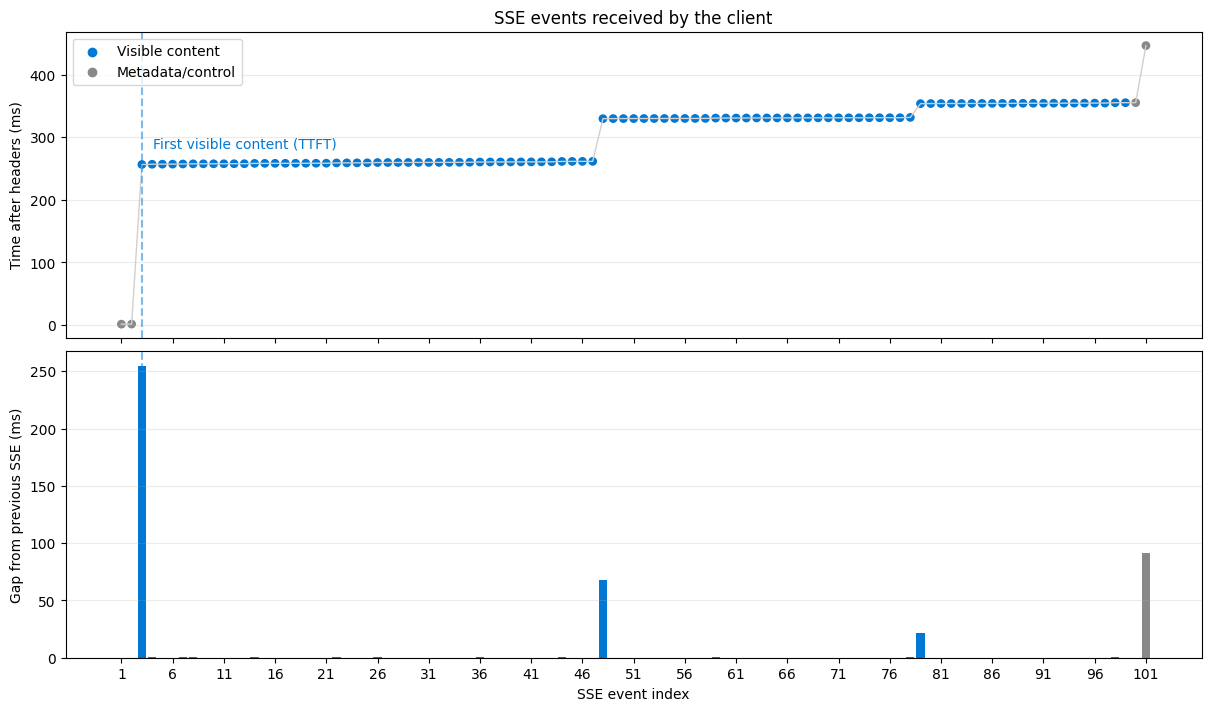

,event_index,event_type,received_from_request_start_ms,received_after_headers_ms,since_previous_sse_received_ms,visible_content,content_chunk_chars
0,1,chat.event,1032.374,1.529,NaN,False,0
1,2,chat.role.delta,1032.507,1.662,0.133,False,0
2,3,chat.content.delta,1287.214,256.368,254.706,True,2
3,4,chat.content.delta,1287.579,256.734,0.366,True,11
4,5,chat.content.delta,1287.746,256.901,0.167,True,1
...,...,...,...,...,...,...,...
96,97,chat.content.delta,1385.261,354.416,0.036,True,3
97,98,chat.content.delta,1385.856,355.011,0.595,True,5
98,99,chat.content.delta,1385.907,355.062,0.051,True,10
99,100,chat.finish,1385.944,355.099,0.037,False,0


Note: Azure does not emit a generated_at timestamp per token/chunk, so generation-to-receipt latency cannot be calculated client-side.


In [38]:
if event_timelines:
    timeline_df = pd.DataFrame(event_timelines[0])
    content_color = "#0078D4"
    other_color = "#8A8886"
    event_colors = timeline_df["visible_content"].map(
        {True: content_color, False: other_color}
    )

    figure, (arrival_axis, gap_axis) = plt.subplots(
        2, 1, figsize=(12, 7), sharex=True, constrained_layout=True
    )

    arrival_axis.plot(
        timeline_df["event_index"],
        timeline_df["received_after_headers_ms"],
        color="#D2D0CE",
        linewidth=1,
    )
    arrival_axis.scatter(
        timeline_df["event_index"],
        timeline_df["received_after_headers_ms"],
        c=event_colors,
        s=28,
    )
    arrival_axis.set_title("SSE events received by the client")
    arrival_axis.set_ylabel("Time after headers (ms)")
    arrival_axis.grid(axis="y", alpha=0.25)
    arrival_axis.scatter([], [], color=content_color, label="Visible content")
    arrival_axis.scatter([], [], color=other_color, label="Metadata/control")
    arrival_axis.legend(loc="upper left")

    gap_axis.bar(
        timeline_df["event_index"],
        timeline_df["since_previous_sse_received_ms"].fillna(0),
        color=event_colors,
        width=0.8,
    )
    gap_axis.set_ylabel("Gap from previous SSE (ms)")
    gap_axis.set_xlabel("SSE event index")
    gap_axis.grid(axis="y", alpha=0.25)

    first_content = timeline_df[timeline_df["visible_content"]].head(1)
    if not first_content.empty:
        first_content_index = int(first_content.iloc[0]["event_index"])
        for axis in (arrival_axis, gap_axis):
            axis.axvline(
                first_content_index, color=content_color, linestyle="--", alpha=0.5
            )
        arrival_axis.annotate(
            "First visible content (TTFT)",
            xy=(
                first_content_index,
                first_content.iloc[0]["received_after_headers_ms"],
            ),
            xytext=(8, 12),
            textcoords="offset points",
            color=content_color,
        )

    tick_step = max(1, len(timeline_df) // 20)
    gap_axis.set_xticks(timeline_df["event_index"].iloc[::tick_step])
    plt.show()

    display(timeline_df)
    print(
        "Note: Azure does not emit a generated_at timestamp per token/chunk, "
        "so generation-to-receipt latency cannot be calculated client-side."
    )

## Cleanup

Run this cell when finished. Re-run the client cell before collecting more samples.

In [ ]:
client.close()
credential.close()
print("Client and credential closed.")